# ⚽ Real-World Data Challenge
## FIFA 19 — What Makes a Top Football Player?
### ⏱️ Time Allowed: 2 – 2.5 Hours &nbsp;|&nbsp; Open: Syntax Sheet &nbsp;|&nbsp; Closed: Internet

---

> **The Story:**
> EA Sports collected detailed data on **18,000+ real professional footballers** for FIFA 19.
> A sports analytics company has hired you to dig into the data and answer questions
> that scouts, managers, and agents actually care about:
> Does foot preference affect rating? Do forwards outperform defenders?
> What best predicts a player's market value?
>
> Your job: **explore, test, visualise, and brief the scouting team.**

---

### 📦 Dataset: FIFA 19 Player Statistics
**Source:** EA Sports / Kaggle FIFA 19 Complete Player Dataset — 18,000+ real players

| Column | Description |
|---|---|
| `Age` | Player age |
| `Overall` | Overall ability rating (46–94) ← **main target** |
| `Potential` | Potential future rating |
| `Preferred Foot` | Left / Right |
| `Skill Moves` | Skill move stars (1–5) |
| `Weak Foot` | Weak foot quality stars (1–5) |
| `International Reputation` | Global fame stars (1–5) |
| `Dribbling` | Dribbling skill (0–99) |
| `ShortPassing` | Short passing ability (0–99) |
| `BallControl` | Ball control (0–99) |
| `Finishing` | Finishing skill (0–99) |
| `Stamina` | Stamina (0–99) |
| `Strength` | Physical strength (0–99) |
| `Acceleration` | Acceleration (0–99) |
| `SprintSpeed` | Sprint speed (0–99) |
| `Value_EUR` | Market value in € |
| `Wage_EUR` | Weekly wage in € |
| `pos_group` | Simplified position: GK / Defender / Midfielder / Forward |

---

### 🧭 Challenge Map

| Task | Topic | Est. Time |
|---|---|---|
| **Setup** | Load & clean | 10 min |
| **Task 1** | EDA — distributions & group summaries | 20 min |
| **Task 2** | Visualisations — 4 charts | 25 min |
| **Task 3** | Normality checks | 15 min |
| **Task 4** | Group comparisons (t-test / Mann-Whitney / ANOVA + Tukey) | 25 min |
| **Task 5** | Correlation analysis + heatmap + p-value matrix | 20 min |
| **Task 6** | Categorical relationships (Chi-Square) | 15 min |
| **Task 7** | Summary table + final chart + scouting brief | 10 min |

---
```
p ≤ 0.05  →  Reject H₀   (something real is happening)
p > 0.05  →  Keep H₀     (could be random chance)
```


---
## ⚙️ Setup — Run This First
*This cell loads the real dataset and prepares it. Do not change it.*

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# ── Load raw FIFA 19 data ─────────────────────────────────────────────────
url = ("https://raw.githubusercontent.com/amanthedorkknight/"
       "fifa18-all-player-statistics/master/2019/data.csv")
raw = pd.read_csv(url)

# ── Clean Value and Wage (convert "€110.5M" → 110500000) ──────────────────
def parse_money(s):
    if pd.isna(s): return np.nan
    s = str(s).replace('€', '').strip()
    if 'M' in s: return float(s.replace('M', '')) * 1_000_000
    if 'K' in s: return float(s.replace('K', '')) * 1_000
    try:    return float(s)
    except: return np.nan

raw['Value_EUR'] = raw['Value'].apply(parse_money)
raw['Wage_EUR']  = raw['Wage'].apply(parse_money)

# ── Simplify position into 4 groups ────────────────────────────────────────
def pos_group(p):
    if pd.isna(p): return None
    p = str(p).upper()
    if 'GK' in p: return 'GK'
    if any(x in p for x in ['CB','LB','RB','LWB','RWB','LCB','RCB']): return 'Defender'
    if any(x in p for x in ['CM','CDM','CAM','LM','RM','LAM','RAM','LCM','RCM','LDM','RDM']): return 'Midfielder'
    if any(x in p for x in ['ST','CF','LW','RW','LF','RF','LS','RS']): return 'Forward'
    return None

raw['pos_group'] = raw['Position'].apply(pos_group)

# ── Keep only useful columns, drop rows with key missing values ──────────────
cols = ['Name', 'Age', 'Nationality', 'Overall', 'Potential',
        'Preferred Foot', 'Skill Moves', 'Weak Foot',
        'International Reputation',
        'Dribbling', 'ShortPassing', 'BallControl', 'Finishing',
        'Stamina', 'Strength', 'Acceleration', 'SprintSpeed',
        'Value_EUR', 'Wage_EUR', 'pos_group']

df = (raw[cols]
      .dropna(subset=['Overall', 'Age', 'Preferred Foot', 'pos_group'])
      .query("pos_group in ['GK', 'Defender', 'Midfielder', 'Forward']")
      .reset_index(drop=True))

print("✅ Dataset ready!")
print(f"   Players : {len(df):,}")
print(f"   Columns : {df.shape[1]}")
print()
print(df['pos_group'].value_counts().to_string())
df.head()


✅ Dataset ready!
   Players : 18,147
   Columns : 20

pos_group
Midfielder    6838
Defender      5866
Forward       3418
GK            2025


,Name,Age,Nationality,Overall,Potential,Preferred Foot,Skill Moves,Weak Foot,International Reputation,Dribbling,ShortPassing,BallControl,Finishing,Stamina,Strength,Acceleration,SprintSpeed,Value_EUR,Wage_EUR,pos_group
0,L. Messi,31,Argentina,94,94,Left,4.0,4.0,5.0,97.0,90.0,96.0,95.0,72.0,59.0,91.0,86.0,110500000.0,565000.0,Forward
1,Cristiano Ronaldo,33,Portugal,94,94,Right,5.0,4.0,5.0,88.0,81.0,94.0,94.0,88.0,79.0,89.0,91.0,77000000.0,405000.0,Forward
2,Neymar Jr,26,Brazil,92,93,Right,5.0,5.0,5.0,96.0,84.0,95.0,87.0,81.0,49.0,94.0,90.0,118500000.0,290000.0,Forward
3,De Gea,27,Spain,91,93,Right,1.0,3.0,4.0,18.0,50.0,42.0,13.0,43.0,64.0,57.0,58.0,72000000.0,260000.0,GK
4,K. De Bruyne,27,Belgium,91,92,Right,4.0,5.0,4.0,86.0,92.0,91.0,82.0,90.0,75.0,78.0,76.0,102000000.0,355000.0,Midfielder


---
## 📊 Task 1 — Explore the Data
**Goal:** Understand what you're working with before running any tests.

---

### 1a. Basic Inspection

Write code to answer:
1. How many players and columns are in `df`?
2. Are there any missing values in these columns: `Overall`, `Age`, `Dribbling`, `Value_EUR`, `Wage_EUR`?
3. What is the average, minimum, and maximum **Overall** rating?
4. How many players are in each **position group** (`pos_group`)?

💡 **Hints:** `.shape` · `.isnull().sum()` · `.describe()` · `.value_counts()`


In [38]:
# 1a — Basic Inspection
print(df.shape)
df.count()

missing_val = ['Overall', 'Age', 'Dribbling', 'Value_EUR', 'Wage_EUR']
missing_count = df[missing_val].isnull().sum()
print(missing_count)

#avg
avg_val = df['Overall'].mean().round(4)
print('\n avg of overall is: ',avg_val)

# max 
max_val = df['Overall'].max()
print('\n Max of overall is: ',max_val)

# min  
min_val = df['Overall'].min()
print('\n Min of overall is: ',min_val)

# players in each position group
player_count = df['pos_group'].value_counts()
print(player_count)

(18147, 20)
Overall      0
Age          0
Dribbling    0
Value_EUR    0
Wage_EUR     0
dtype: int64

 avg of overall is:  66.2539

 Max of overall is:  94

 Min of overall is:  46
pos_group
Midfielder    6838
Defender      5866
Forward       3418
GK            2025
Name: count, dtype: int64


---
### 1b. Group Summaries

Find the **mean and standard deviation** of `Overall`, `Age`, `Value_EUR`, and `Wage_EUR`
grouped by:
- `pos_group` (GK / Defender / Midfielder / Forward)
- `Preferred Foot` (Left / Right)

💡 **Hint:** `df.groupby('col')[['Overall','Age']].agg(['mean','std']).round(2)`


In [39]:
summary_columns = ['Overall', 'Age', 'Value_EUR', 'Wage_EUR']

position_summary = (
    df.groupby('pos_group')[summary_columns]
      .agg(['mean', 'std'])
      .round(2)
)

foot_summary = (
    df.groupby('Preferred Foot')[summary_columns]
      .agg(['mean', 'std'])
      .round(2)
)

print("Summary by position group:")
print(position_summary)

print("\nSummary by preferred foot:")
print(foot_summary)

Summary by position group:
           Overall          Age         Value_EUR              Wage_EUR  \
              mean   std   mean   std        mean         std      mean   
pos_group                                                                 
Defender     66.40  6.46  25.47  4.52  1975138.08  4106420.51   9146.10   
Forward      66.40  7.02  24.66  4.61  2984155.94  7395815.54  11718.26   
GK           64.60  7.60  26.04  5.47  1585814.81  4562890.61   6803.95   
Midfielder   66.55  6.96  24.78  4.51  2760639.08  5890612.59  10180.61   

                      
                 std  
pos_group             
Defender    18970.31  
Forward     28662.56  
GK          16719.63  
Midfielder  21932.88  

Summary by preferred foot:
               Overall          Age         Value_EUR              Wage_EUR  \
                  mean   std   mean   std        mean         std      mean   
Preferred Foot                                                                
Left             66.8

---
### 1c. Written Observations ✍️

Fill in the blanks after running your code:

```
1. The dataset has 18147 players and 20 columns.

2. Missing values found in:
   Overall - 0  Age - 0  Dribbling - 0
   Value_EUR - 0  Wage_EUR - 0

3. Overall rating → Mean: 66.2539 Min: 46  Max: 94

4. Position group counts:
   GK: 2025   Defender: 5866    Midfielder: 6838    Forward: 3418

5. Which position group has the highest average Overall? Midfielder 66.55

6. Do left-footed or right-footed players have a higher average Overall? yes, 
leftfooted by 66.80 (Left) − 66.09 (Right) = 0.71 rating points.

```

## 🎨 Task 2 — Visualisations
**Goal:** See the data. Statistics without charts are blind.
---
### 2a. The Big Four — 2×2 Subplot Grid

Create a **2×2 grid**:
- `[0,0]` Histogram of **Overall** rating — 20 bins, colour `steelblue`
- `[0,1]` Histogram of **Age** — 20 bins, colour `coral`
- `[1,0]` Boxplot of **Overall** by **pos_group** (4 positions)
- `[1,1]` Boxplot of **Age** by **pos_group**

Every subplot needs **title, xlabel, ylabel**. Write one `# observation:` comment per plot.

💡 **Hints:**  
`ax.hist(df['Overall'], bins=20, color='steelblue', edgecolor='white')`  
`df.boxplot(column='Overall', by='pos_group', ax=axes[1,0])`  
`plt.suptitle(...)` · `plt.tight_layout()`

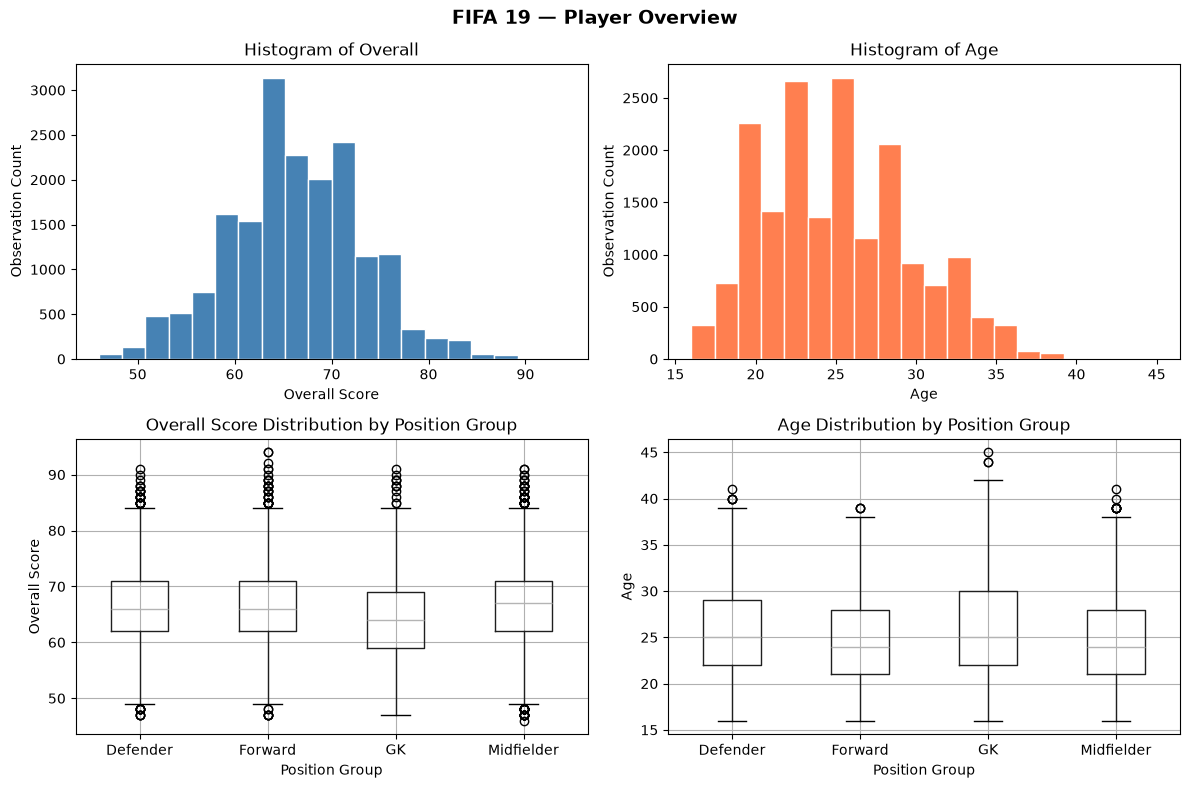

In [40]:
# 2a — 2×2 Subplot Grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# [0,0] Histogram of Overall
ax = axes[0, 0]
ax.hist(df['Overall'], bins=20, color='steelblue', edgecolor='white')
ax.set_title('Histogram of Overall')
ax.set_xlabel('Overall Score')
ax.set_ylabel('Observation Count')

# [0,1] Histogram of Age
ax = axes[0, 1]
ax.hist(df['Age'], bins=20, color='coral', edgecolor='white')
ax.set_title('Histogram of Age')
ax.set_xlabel('Age')
ax.set_ylabel('Observation Count')

# [1,0] Boxplot: Overall by pos_group
ax = axes [1, 0]
df.boxplot(column='Overall', by='pos_group', ax=ax)
ax.set_title('Overall Score Distribution by Position Group')
ax.set_xlabel('Position Group')
ax.set_ylabel('Overall Score')

# [1,1] Boxplot: Age by pos_group
ax = axes[1,1]
df.boxplot(column='Age', by='pos_group', ax=ax)
ax.set_title('Age Distribution by Position Group')
ax.set_xlabel('Position Group')
ax.set_ylabel('Age')

plt.suptitle('FIFA 19 — Player Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


---
### 2b. Scatter Plot — Age vs Overall Rating

Create a scatter plot of **Age** (x) vs **Overall** (y).
- Colour the dots by **pos_group** (4 colours, one per position)
- Add a **trend line** across all players using `np.polyfit`
- Proper title, xlabel, ylabel, legend

💡 **Hints:**  
`sns.scatterplot(data=df, x='Age', y='Overall', hue='pos_group', alpha=0.4, ax=ax)`  
`m, b = np.polyfit(df['Age'], df['Overall'], 1)`  
`x_line = np.linspace(df['Age'].min(), df['Age'].max(), 100)`  
`ax.plot(x_line, m*x_line + b, color='black', linewidth=2, linestyle='--')`

> After plotting — does the trend line go up or down? What does that mean for a player's career?


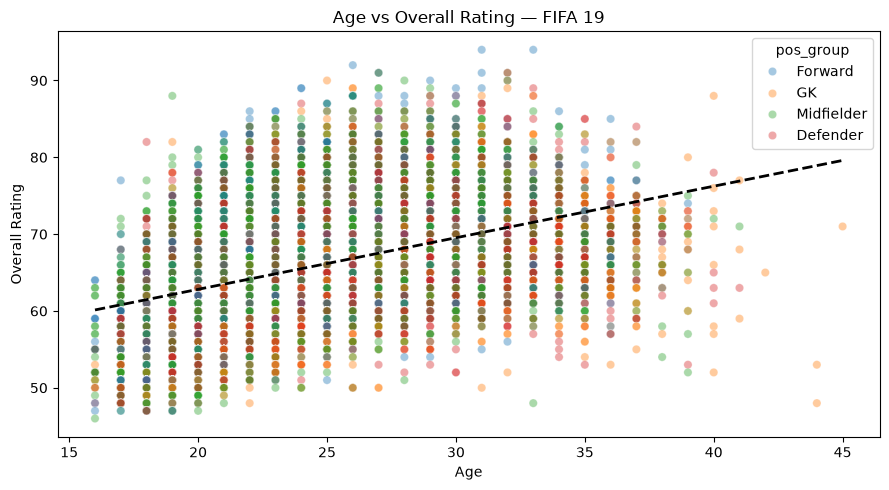

In [41]:
# 2b — Scatter: Age vs Overall
fig, ax = plt.subplots(figsize=(9, 5))

# Scatter coloured by pos_group
sns.scatterplot(data=df, x='Age', y='Overall', hue='pos_group', alpha=0.4, ax=ax)
# 2. Calculate the linear regression line coefficients (slope 'm' and intercept 'b')
m, b = np.polyfit(df['Age'], df['Overall'], 1)
# 3. Generate 100 points across the data's X range to draw a smooth line
x_line = np.linspace(df['Age'].min(), df['Age'].max(), 100)
# 4. Plot the dashed black trend line
ax.plot(x_line, m * x_line + b, color="black", linewidth=2, linestyle="--")

ax.set_title('Age vs Overall Rating — FIFA 19')
ax.set_xlabel('Age')
ax.set_ylabel('Overall Rating')
plt.tight_layout()
plt.show()

# Trend direction: ___________________________________ positive, meaning going upwards
# What does this suggest about player development? ___________________________ with increase in age the players become more experienced


---
### 2c. Bar Chart — Average Overall by Position (with Error Bars)

Create a **bar chart** showing the average Overall for each `pos_group`.
- Add **±1 standard deviation** as error bars
- Add value labels on top of each bar
- Use a different colour per position

💡 **Hints:**
```python
grouped = df.groupby('pos_group')['Overall'].agg(['mean','std']).reset_index()
ax.bar(grouped['pos_group'], grouped['mean'],
       yerr=grouped['std'], capsize=5, color=[...], edgecolor='black')
for bar, m in zip(bars, grouped['mean']):
    ax.text(bar.get_x() + bar.get_width()/2, m + 1, f'{m:.1f}', ha='center')
```


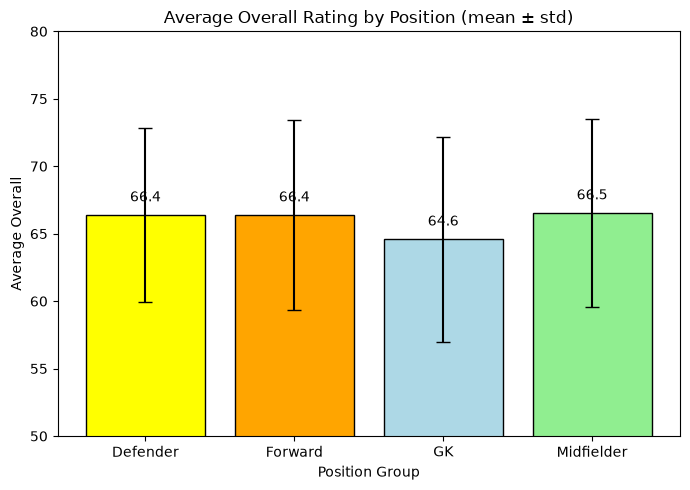

In [42]:
# 2c — Bar Chart: Average Overall by Position
fig, ax = plt.subplots(figsize=(7, 5))
# Group data
grouped = df.groupby('pos_group')['Overall'].agg(['mean','std']).reset_index()

# Draw bars with error bars
bars = ax.bar(grouped['pos_group'], 
              grouped['mean'], 
              yerr= grouped['std'], 
              capsize=5, 
              color=['yellow', 'orange', 'lightblue', 'lightgreen'], 
              edgecolor='black'
              )

# Add value labels on top of each bar
for bar, m in zip(bars, grouped['mean']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        m + 1, f'{m:.1f}', ha='center'
    )

ax.set_title('Average Overall Rating by Position (mean ± std)')
ax.set_xlabel('Position Group')
ax.set_ylabel('Average Overall')
ax.set_ylim(50, 80)
plt.tight_layout()
plt.show()


---
## 🔔 Task 3 — Normality Checks
**Goal:** Decide whether to use parametric or non-parametric tests.
---

### 3a. Shapiro-Wilk Test

Run Shapiro-Wilk on: `Overall`, `Age`, `Dribbling`, `Strength`, `Value_EUR`

> ⚠️ **Note:** Shapiro-Wilk is designed for small samples. On large datasets (n > 5000),
> it almost always gives p ≈ 0. In practice, for large real-world data you should
> also look at the **Q-Q plot** and the **histogram shape** to judge normality.
> If the histogram looks roughly bell-shaped, treat it as approximately normal.

Print a clean table with column name, p-value, and your judgement.

💡 **Hints:** `stat, p = stats.shapiro(df['col'].sample(500, random_state=42))` — sample 500 rows for Shapiro


In [43]:
# 3a — Shapiro-Wilk (on a 500-row sample per column)

shape_judgements = {
    'Overall': 'Discrete / slightly non-normal',
    'Age': 'Discrete / moderately non-normal',
    'Dribbling': 'Non-normal',
    'Strength': 'Non-normal',
    'Value_EUR': 'Strongly right-skewed'
}

columns_to_test = [
    'Overall', 'Age', 'Dribbling', 'Strength', 'Value_EUR'
]

print(f"{'Column':<15} {'p-value':>12} {'Normal?':>12} {'Shape':>28}")
print("-" * 72)

for col in columns_to_test:
    sample = df[col].dropna().sample(500, random_state=42)
    stat, p = stats.shapiro(sample)

    normal = 'Yes' if p > 0.05 else 'No'
    shape = shape_judgements[col]

    print(f"{col:<15} {p:>12.6g} {normal:>12} {shape:>28}")

Column               p-value      Normal?                        Shape
------------------------------------------------------------------------
Overall            0.0165086           No Discrete / slightly non-normal
Age              8.49385e-08           No Discrete / moderately non-normal
Dribbling        2.56786e-20           No                   Non-normal
Strength         4.88681e-06           No                   Non-normal
Value_EUR        2.77078e-35           No        Strongly right-skewed


---
### 3b. Q-Q Plots

Create a **1×5 grid of Q-Q plots** for the same five columns.
- Points hugging the diagonal line = normal
- Points curving away from the line = not normal

💡 **Hint:** `stats.probplot(df['col'].dropna(), plot=axes[i])`


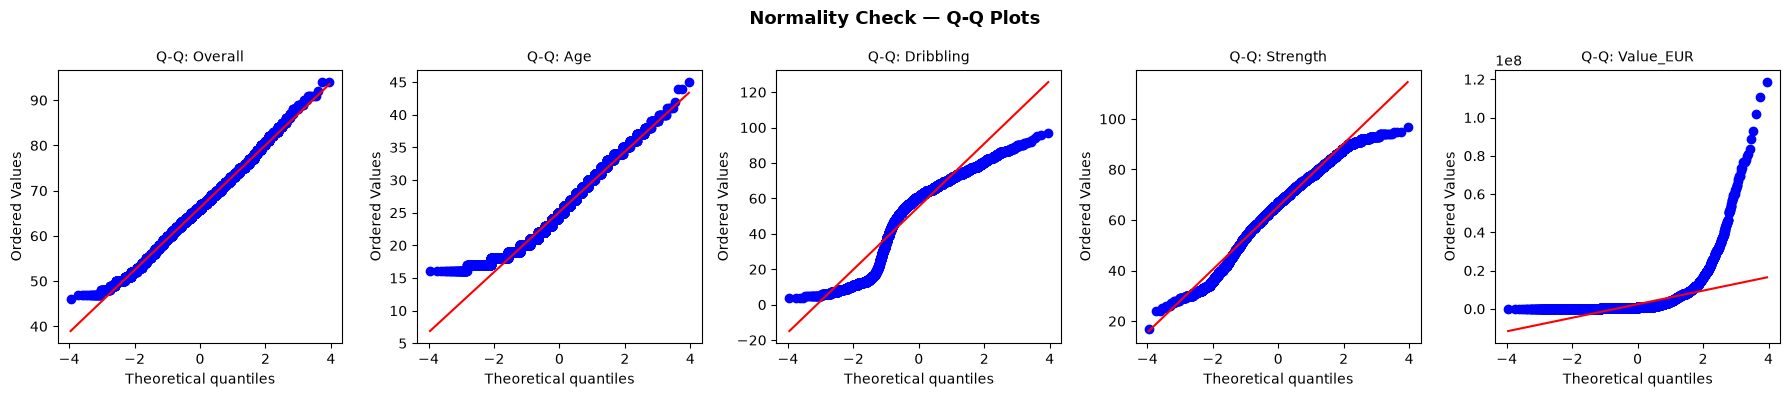

In [44]:
# 3b — Q-Q Plots
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, col in enumerate(['Overall', 'Age', 'Dribbling', 'Strength', 'Value_EUR']):
    stats.probplot(df[col].dropna(), plot=axes[i])
    axes[i].set_title(f'Q-Q: {col}', fontsize=10)

plt.suptitle('Normality Check — Q-Q Plots', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
### 3c. Your Decision Table ✍️

Fill this in — it determines which tests you use in Tasks 4 and 5:

| Column | Histogram Shape | Q-Q Shape | Treat as Normal? | → Use for groups | → Use for relationship |
|---|---|---|---|---|---|
| Overall | | | | t-test / Mann-Whitney | Pearson / Spearman |
| Age | | | | | |
| Dribbling | | | | | |
| Strength | | | | | |
| Value_EUR | | | | | |

> 💡 If ANY group in a comparison is non-normal → use non-parametric.

Answer

| Column    | Histogram shape             | Q-Q shape                           | Treat as normal? | Group test                     | Relationship test |
| --------- | --------------------------- | ----------------------------------- | ---------------- | ------------------------------ | ----------------- |
| Overall   | Discrete, mildly non-normal | Deviates from diagonal at the tails | No               | Mann–Whitney or Kruskal–Wallis | Spearman          |
| Age       | Discrete, moderately skewed | Curved away from diagonal           | No               | Mann–Whitney or Kruskal–Wallis | Spearman          |
| Dribbling | Bounded and non-normal      | Noticeable curvature                | No               | Mann–Whitney or Kruskal–Wallis | Spearman          |
| Strength  | Bounded and non-normal      | Noticeable curvature                | No               | Mann–Whitney or Kruskal–Wallis | Spearman          |
| Value_EUR | Strongly right-skewed       | Strong deviation from diagonal      | No               | Mann–Whitney or Kruskal–Wallis | Spearman          |





---
## 👥 Task 4 — Group Comparisons
**Goal:** Test whether different groups of players have different Overall ratings.

---

### 4a. Do Left-Footed vs Right-Footed Players Differ in Overall?

**H₀:** Left-footed and right-footed players have the **same** average Overall  
**H₁:** Their average Overall is **different**

Steps:
1. Extract Overall for each foot group
2. Check normality of each group (Shapiro — sample 500)
3. Based on normality → choose **t-test** or **Mann-Whitney U**
4. Run the test, print statistic, p-value, verdict

💡 **Hints:**  
`left  = df[df['Preferred Foot'] == 'Left']['Overall']`  
`stats.ttest_ind(left, right)` or `stats.mannwhitneyu(left, right, alternative='two-sided')`


In [45]:
# 4a — Left-Footed vs Right-Footed: Overall Rating

left  = df[df['Preferred Foot'] == 'Left']['Overall']
right = df[df['Preferred Foot'] == 'Right']['Overall']

print(f"Left foot  — mean: {left.mean():.2f}  std: {left.std():.2f}  n: {len(left)}")
print(f"Right foot — mean: {right.mean():.2f}  std: {right.std():.2f}  n: {len(right)}")
print()

# H₀: ________________________________________ Left footed and right footed players have same average
# H₁: ________________________________________ Left footed and right footed players don't have same average

# Step 2: Normality check (sample 500 each)
left_sample = left.sample(500, random_state=42)
right_sample = right.sample(500, random_state=42)

left_shapiro = stats.shapiro(left_sample)
right_shapiro = stats.shapiro(right_sample)

print("Normality Test (Shapiro-Wilk)")
print(f"Left foot  — statistic: {left_shapiro.statistic:.4f}, p-value: {left_shapiro.pvalue:.4f}")
print(f"Right foot — statistic: {right_shapiro.statistic:.4f}, p-value: {right_shapiro.pvalue:.4f}")
print()

# Step 3 & 4: Run chosen test and print verdict
alpha = 0.05
if left_shapiro.pvalue > alpha and right_shapiro.pvalue > alpha:
    # Both groups are approximately normal → Independent t-test
    test_name = 'Independent t-test'
    result = stats.ttest_ind(left, right)
else:
    # At least one group is not normal → Mann-Whitney U
    test_name = "Mann-Whitney U test"
    result = stats.mannwhitneyu(left, right, alternative='two-sided')

print(f"Chosen test: {test_name}")
print(f"Statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")

if result.pvalue < alpha:
    print("Verdict: Rejected H₀ — Left-footed and right-footed players have a statistically significant difference in Overall ratings.")
else:
    print("Verdict: Can.t reject H₀ — Left-footed and right-footed players don't have a statistically significant difference in Overall ratings.")


Left foot  — mean: 66.80  std: 6.56  n: 4209
Right foot — mean: 66.09  std: 7.01  n: 13938

Normality Test (Shapiro-Wilk)
Left foot  — statistic: 0.9919, p-value: 0.0082
Right foot — statistic: 0.9942, p-value: 0.0547

Chosen test: Mann-Whitney U test
Statistic: 30999381.0000
p-value: 0.0000
Verdict: Rejected H₀ — Left-footed and right-footed players have a statistically significant difference in Overall ratings.


---
### 4b. Do Forwards Score Higher in Overall than Defenders?

Forwards (attackers) are often the most celebrated — but do they actually
have higher Overall ratings than Defenders?

**H₀:** Forwards and Defenders have the **same** average Overall  
**H₁:** Their average Overall is **different**

Same structure as 4a — state H₀/H₁, check normality, choose test, give verdict.


In [46]:
# 4b — Forwards vs Defenders: Overall Rating

# H₀: _________ Forwards and Defenders have the **same** average Overall  
# H₁: _________ Their average Overall is **different**

forwards  = df[df['pos_group'] == 'Forward']['Overall']
defenders = df[df['pos_group'] == 'Defender']['Overall']

print(f"Forwards  — mean: {forwards.mean():.2f}  n: {len(forwards)}")
print(f"Defenders — mean: {defenders.mean():.2f}  n: {len(defenders)}")
print()

# Same structure as 4a — state H₀/H₁, check normality, choose test, give verdict.

# Normality check
forward_sample = forwards.sample(500, random_state=42)
defender_sample = defenders.sample(500, random_state=42)

forward_shapiro = stats.shapiro(forward_sample)
defender_shapiro = stats.shapiro(defender_sample)

print("Normality Test (Shapiro-Wilk)")
print(f"Forwards  — statistic: {forward_shapiro.statistic:.4f}, p-value: {forward_shapiro.pvalue:.4f}")
print(f"Defenders — statistic: {defender_shapiro.statistic:.4f}, p-value: {defender_shapiro.pvalue:.4f}")
print()

# Test & Verdict
alpha = 0.05
if forward_shapiro.pvalue > alpha and defender_shapiro.pvalue > alpha:

    # Both groups are normal → Independent t-test
    test_name = "Independent t-test"
    result = stats.ttest_ind(forwards, defenders)

else:

    # At least one group is not normal → Mann-Whitney U test
    test_name = "Mann-Whitney U test"
    result = stats.mannwhitneyu(
        forwards,
        defenders,
        alternative='two-sided'
    )

# Step 4: Test result and verdict

print(f"Chosen test: {test_name}")
print(f"Statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")

if result.pvalue < alpha:
    print("Verdict: Reject H₀ — There is a statistically significant difference.")
else:
    print("Verdict: Fail to reject H₀ — There is not enough evidence of a difference.")


Forwards  — mean: 66.40  n: 3418
Defenders — mean: 66.40  n: 5866

Normality Test (Shapiro-Wilk)
Forwards  — statistic: 0.9966, p-value: 0.3852
Defenders — statistic: 0.9940, p-value: 0.0464

Chosen test: Mann-Whitney U test
Statistic: 10019183.5000
p-value: 0.9628
Verdict: Fail to reject H₀ — There is not enough evidence of a difference.


---
### 4c. Do All 4 Position Groups Differ in Overall? → ANOVA / Kruskal-Wallis

**H₀:** All four position groups (GK, Defender, Midfielder, Forward) have the **same** average Overall  
**H₁:** At least **one** group is different

Steps:
1. Build a list of Overall rating arrays — one per position group
2. Check normality on at least 2 groups
3. Run **ANOVA** (if normal) or **Kruskal-Wallis** (if not normal)
4. If p ≤ 0.05 → run **Tukey post-hoc** to find which pairs differ

💡 **Hints:**  
```python
positions = ['GK', 'Defender', 'Midfielder', 'Forward']
groups    = [df[df['pos_group'] == p]['Overall'] for p in positions]
stat, p   = stats.f_oneway(*groups)   # ANOVA
# OR
stat, p   = stats.kruskal(*groups)    # Kruskal-Wallis

# Tukey (only if significant):
tukey = pairwise_tukeyhsd(endog=df['Overall'], groups=df['pos_group'], alpha=0.05)
print(tukey.summary())
```


In [47]:
# 4c — ANOVA / Kruskal-Wallis: Position Group vs Overall

positions = ['GK', 'Defender', 'Midfielder', 'Forward']
groups    = [df[df['pos_group'] == p]['Overall'] for p in positions]

print("Group means:")
for pos, g in zip(positions, groups):
    print(f"  {pos:<12}: mean={g.mean():.2f}  std={g.std():.2f}  n={len(g)}")
print()

# H₀: All four position groups have the same average Overall
# H₁: At least one position group has a different average Overall

# Normality check on 2 groups (sample 500)
gk_sample = groups[0].sample(500, random_state=42)
defender_sample = groups[1].sample(500, random_state=42)

gk_shapiro = stats.shapiro(gk_sample)
defender_shapiro = stats.shapiro(defender_sample)

print("Normality Test (Shapiro-Wilk)")
print(f"GK — statistic: {gk_shapiro.statistic:.4f}, p-value: {gk_shapiro.pvalue:.4f}")
print(f"Defender — statistic: {defender_shapiro.statistic:.4f}, p-value: {defender_shapiro.pvalue:.4f}")
print()

# Run ANOVA or Kruskal-Wallis

alpha = 0.05

if gk_shapiro.pvalue > alpha and defender_shapiro.pvalue > alpha:
    # Normal → One-way ANOVA
    test_name = "One-way ANOVA"
    stat, p = stats.f_oneway(*groups)
else:
    # Not normal → Kruskal-Wallis
    test_name = "Kruskal-Wallis"
    stat, p = stats.kruskal(*groups)

print(f"Chosen test: {test_name}")
print(f"Statistic: {stat:.4f}")
print(f"p-value: {p:.4f}")

if p <= alpha:
    print("Verdict: Reject H₀ — At least one position group is significantly different.")

    # Step 5: Tukey post-hoc
    print("\nTukey Post-Hoc Test:")
    
    tukey = pairwise_tukeyhsd(
        endog=df['Overall'],
        groups=df['pos_group'],
        alpha=0.05
    )
    print(tukey.summary())
else:
    print("Verdict: Fail to reject H₀ — There is not enough evidence that the position groups differ.")


Group means:
  GK          : mean=64.60  std=7.60  n=2025
  Defender    : mean=66.40  std=6.46  n=5866
  Midfielder  : mean=66.55  std=6.96  n=6838
  Forward     : mean=66.40  std=7.02  n=3418

Normality Test (Shapiro-Wilk)
GK — statistic: 0.9919, p-value: 0.0078
Defender — statistic: 0.9940, p-value: 0.0464

Chosen test: Kruskal-Wallis
Statistic: 131.5085
p-value: 0.0000
Verdict: Reject H₀ — At least one position group is significantly different.

Tukey Post-Hoc Test:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
 group1    group2   meandiff p-adj   lower   upper  reject
----------------------------------------------------------
Defender    Forward  -0.0031    1.0 -0.3839  0.3778  False
Defender         GK  -1.7966    0.0 -2.2528 -1.3405   True
Defender Midfielder   0.1457 0.6343 -0.1693  0.4607  False
 Forward         GK  -1.7936    0.0 -2.2899 -1.2972   True
 Forward Midfielder   0.1488 0.7313  -0.222  0.5195  False
      GK Midfielder   1.9423    0.0  1.4945  2.3901   

In [ ]:
# 4c continued — Tukey Post-hoc

# Run only if your test above was significant (p ≤ 0.05)

# tukey = pairwise_tukeyhsd(endog=df['Overall'], groups=df['pos_group'], alpha=0.05)
# print(tukey.summary())

# Which pairs are significantly different? (look for reject=True rows)
# Ans: Defender, Forward, and Midfielder. The main pattern is that 
# goalkeepers have lower Overall ratings than the other three groups.


---
## 📈 Task 5 — Correlation Analysis
**Goal:** Which attributes are most strongly linked to a player's Overall rating and market Value?

---

### 5a. Correlation Heatmap

Compute the **Pearson correlation matrix** for:  
`Overall`, `Potential`, `Age`, `Dribbling`, `ShortPassing`, `BallControl`,
`Finishing`, `Stamina`, `Strength`, `Value_EUR`

Display it as a **heatmap** — use `coolwarm`, annotated, values from -1 to +1.

💡 **Hints:**  
`corr = df[cols].corr()`  
`sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)`


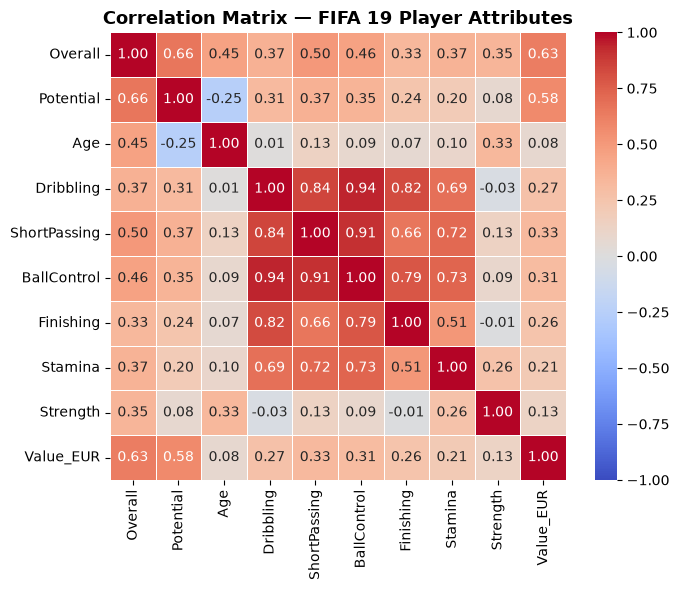

In [48]:
# 5a — Correlation Matrix Heatmap
cols = ['Overall', 'Potential', 'Age', 'Dribbling', 'ShortPassing',
          'BallControl', 'Finishing', 'Stamina', 'Strength', 'Value_EUR']

corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix — FIFA 19 Player Attributes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Which attribute is most positively correlated with Overall? ___ potential 
# Which attribute is most negatively correlated with Value_EUR? ____ age. 


---
### 5b. Hypothesis Tests on Three Key Relationships

Test these claims:

**Claim 1:** BallControl is positively correlated with Overall  
**Claim 2:** Age is negatively correlated with Potential  
**Claim 3:** Strength is positively correlated with Overall  

For each:
1. State H₀ and H₁
2. Choose Pearson **or** Spearman (based on Task 3 normality decisions)
3. Run the test → report correlation coefficient (r or ρ), p-value, verdict
4. Write one sentence of plain-English interpretation

💡 **Hints:**  
`r, p = stats.pearsonr(df['BallControl'], df['Overall'])`  
`rho, p = stats.spearmanr(df['Age'], df['Potential'])`


In [49]:
# 5b — Correlation Tests

# ── Claim 1: BallControl vs Overall 
# H0: ____ There is no correlation between BallControl and Overall.
# H1: ____ BallControl is positively correlated with Overall

r, p = stats.pearsonr(df['BallControl'], df['Overall'])
print(f"Correlation Coefficient: {r:.4f}, p-value: {p}")
# Interpretation: _____ Interpretation: If (p < 0.05), reject H_0: There is a statistically 
# significant positive relationship between a player's ball control and their overall rating. 

# ── Claim 2: Age vs Potential ────────────────────────────────────────────────
# H0: There is no correlation between Age and Potential.
# H1: Age is negatively correlated with Potential (rho < 0).

# Assuming non-normal distribution (Spearman) as typical for Age/Potential
rho, p = stats.spearmanr(df['Age'], df['Potential'])
print(f"Correlation Coefficient: {rho:.4f}, p-value: {p}")

# Interpretation: ---- Interpretation: If (p < 0.05), reject H_0: There is a statistically significant 
# negative relationship showing that a player's potential rating tends to decrease as age increases. 

# ── Claim 3: Strength vs Overall ────────────────────────────────────────────
# H_0: There is no correlation between Strength and Overall (rho <= leq 0).
# H_1: Strength is positively correlated with Overall (rho > 0).

# Assuming normal distribution (Pearson), use stats.spearmanr if non-normal
r, p = stats.pearsonr(df['Strength'], df['Overall'])
print(f"Correlation Coefficient: {r:.4f}, p-value: {p}")

# Interpretation: --- If (p < 0.05), reject H_0: There is a statistically significant 
# positive relationship showing that stronger players tend to have higher overall ratings.


Correlation Coefficient: 0.4600, p-value: 0.0
Correlation Coefficient: -0.2623, p-value: 3.6277019017422717e-283
Correlation Coefficient: 0.3493, p-value: 0.0


---
### 5c. p-value Matrix — Which Correlations Are Significant? (⭐ Challenge)

Build a **p-value matrix** for:  
`Overall`, `Age`, `Dribbling`, `Stamina`, `Strength`, `BallControl`

Then display a heatmap **masking non-significant pairs** (p > 0.05) — only
show the cells where the relationship is statistically real.

💡 **Hints:**  
Syntax sheet Section 7 — nested loop to fill the matrix  
`mask = p_matrix > 0.05`  
`sns.heatmap(p_matrix, mask=mask, annot=True, fmt='.3f', cmap='Reds_r', vmin=0, vmax=0.05)`


P-value matrix:
             Overall  Age  Dribbling  Stamina  Strength  BallControl
Overall          NaN  0.0        0.0      0.0       0.0          0.0
Age              0.0  NaN        0.0      0.0       0.0          0.0
Dribbling        0.0  0.0        NaN      0.0       0.0          0.0
Stamina          0.0  0.0        0.0      NaN       0.0          0.0
Strength         0.0  0.0        0.0      0.0       NaN          0.0
BallControl      0.0  0.0        0.0      0.0       0.0          NaN


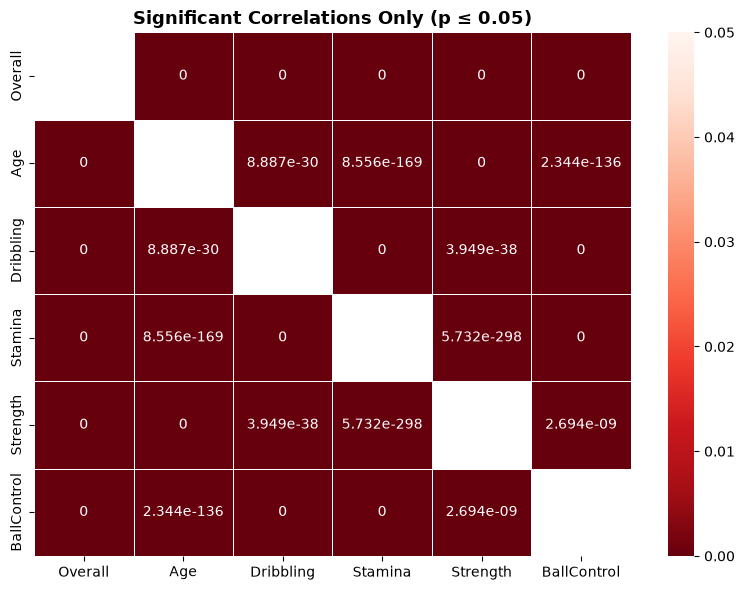

In [54]:
# 5c — Significant p-value Matrix

cols5c = [
    'Overall',
    'Age',
    'Dribbling',
    'Stamina',
    'Strength',
    'BallControl'
]

# Create an empty writable p-value matrix
p_matrix = pd.DataFrame(
    np.nan,
    index=cols5c,
    columns=cols5c,
    dtype=float
)

# Fill the off-diagonal cells with Spearman p-values
for c1 in cols5c:
    for c2 in cols5c:
        if c1 != c2:
            _, p_value = stats.spearmanr(
                df[c1],
                df[c2]
            )
            p_matrix.loc[c1, c2] = p_value

# Keep the diagonal as NaN.
# It is already NaN, so no np.fill_diagonal() is needed.

print("P-value matrix:")
print(p_matrix.round(6))

# Mask non-significant values and diagonal NaN values
mask = (
    (p_matrix > 0.05)
    | p_matrix.isna()
)

# Plot only statistically significant p-values
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    p_matrix,
    mask=mask,
    annot=True,
    fmt='.4g',
    cmap='Reds_r',
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    linecolor='white',
    ax=ax
)

ax.set_title(
    'Significant Correlations Only (p ≤ 0.05)',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

---
## 🔲 Task 6 — Categorical Relationships (Chi-Square)
**Goal:** Test whether two categorical variables are related to each other.

---

### 6a. Is Preferred Foot linked to Position Group?

Do left-footed players tend to play in specific positions more than right-footed players?

**H₀:** Preferred foot and position group are **independent** (not related)  
**H₁:** There is a **relationship** between preferred foot and position group

Steps:
1. Build a crosstab of `Preferred Foot` vs `pos_group`
2. Calculate and display **row percentages**
3. Run Chi-Square test
4. Print verdict

💡 **Hints:**  
`table = pd.crosstab(df['Preferred Foot'], df['pos_group'])`  
`row_pct = table.div(table.sum(axis=1), axis=0).round(2)`  
`chi2, p, dof, expected = stats.chi2_contingency(table)`


In [19]:
# 6a — Preferred Foot vs Position Group

# Crosstab (counts)
table = pd.crosstab(df['Preferred Foot'], df['pos_group'])
print("\nFrequency Table:")
print(table)

# Row percentages
row_pct = table.div(table.sum(axis=1), axis=0).round(2)
print("\nRow Percentages:")
print(row_pct)

# Chi-Square test
chi2, p, dof, expected = stats.chi2_contingency(table)

print("\nChi-Square Test:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"p-value: {p:.10f}")
print(f"Degrees of freedom: {dof}")

# Verdict & Interpretation:
if p <= 0.05:
    print("Verdict: Reject H₀ — Preferred foot and position group are significantly related.")
else:
    print("Verdict: Fail to reject H₀ — No significant relationship between preferred foot and position group.")
# ___________________________________________________



Frequency Table:
pos_group       Defender  Forward    GK  Midfielder
Preferred Foot                                     
Left                1884      596   206        1523
Right               3982     2822  1819        5315

Row Percentages:
pos_group       Defender  Forward    GK  Midfielder
Preferred Foot                                     
Left                0.45     0.14  0.05        0.36
Right               0.29     0.20  0.13        0.38

Chi-Square Test:
Chi-square statistic: 521.7735
p-value: 0.0000000000
Degrees of freedom: 3
Verdict: Reject H₀ — Preferred foot and position group are significantly related.


---
### 6b. Is Skill Moves Level Linked to Position Group?

Skill Moves range from 1–5 stars. Players with 4–5 stars are elite dribblers.
Create a new column `skill_tier`: **'High'** (Skill Moves ≥ 4) vs **'Low'** (Skill Moves < 4).

Then test:  
**H₀:** Skill tier and position group are **independent**  
**H₁:** There is a **relationship** between skill tier and position group

Full solution — no starter code. State H₀/H₁, build crosstab, show row %, run Chi-Square, give verdict.


In [ ]:
# 6b.
df['skill_tier'] = np.where(df['Skill Moves'] >= 4, 'High', 'Low')

skill_table = pd.crosstab(
    df['skill_tier'],
    df['pos_group']
)

skill_row_pct = (
    skill_table
    .div(skill_table.sum(axis=1), axis=0)
    .round(4)
)

print("Frequency table:")
print(skill_table)

print("\nRow percentages:")
print(skill_row_pct)

chi2, p, dof, expected = stats.chi2_contingency(skill_table)

print("\nChi-Square test:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"p-value: {p:.10f}")
print(f"Degrees of freedom: {dof}")

if p <= 0.05:
    print("Reject H₀ — Skill tier and position group are significantly related.")
else:
    print("Fail to reject H₀ — No significant relationship was detected.")

Frequency table:
pos_group   Defender  Forward    GK  Midfielder
skill_tier                                     
High              48      312     0         608
Low             5818     3106  2025        6230

Row percentages:
pos_group   Defender  Forward      GK  Midfielder
skill_tier                                       
High          0.0496   0.3223  0.0000      0.6281
Low           0.3387   0.1808  0.1179      0.3627

Chi-Square test:
Chi-square statistic: 619.7948
p-value: 0.0000000000
Degrees of freedom: 3
Reject H₀ — Skill tier and position group are significantly related.


---
### 6c. Visualise the Crosstabs

Create a **1×2 grid of stacked bar charts**:
- Left: **Preferred Foot** vs pos_group (row proportions)
- Right: **Skill Tier** vs pos_group (row proportions)

💡 **Hint:**
```python
row_pct.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2', edgecolor='black')
axes[0].tick_params(axis='x', rotation=0)
```


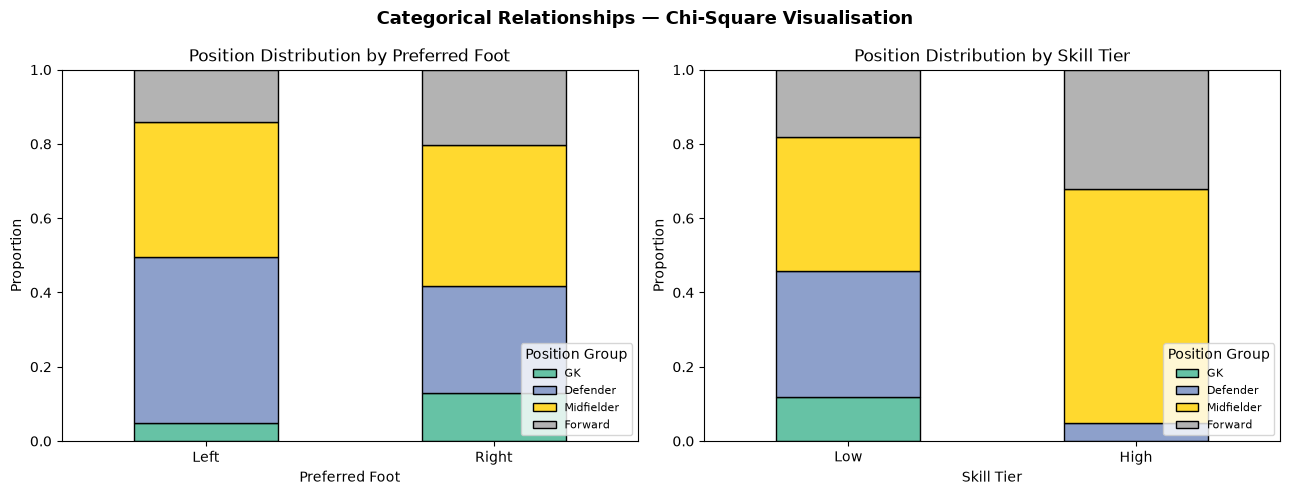

In [ ]:
# 6c — Stacked Bar Charts

# Optional safety check
if 'skill_tier' not in df.columns:
    raise KeyError(
        "skill_tier is missing. Run the Task 6b cell first."
    )

# Create a 1×2 figure
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Define a consistent order for all position groups
position_order = ['GK', 'Defender', 'Midfielder', 'Forward']

# LEFT: Preferred Foot vs Position Group

foot_table = pd.crosstab(
    df['Preferred Foot'],
    df['pos_group']
)

# Ensure the position columns use the same order
foot_table = foot_table.reindex(
    columns=position_order,
    fill_value=0
)

# Convert counts into row proportions
foot_pct = foot_table.div(
    foot_table.sum(axis=1),
    axis=0
)

foot_pct.plot(
    kind='bar',
    stacked=True,
    ax=axes[0],
    colormap='Set2',
    edgecolor='black'
)

axes[0].set_title('Position Distribution by Preferred Foot')
axes[0].set_xlabel('Preferred Foot')
axes[0].set_ylabel('Proportion')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(
    title='Position Group',
    loc='lower right',
    fontsize=8
)

# observation:
# Left- and right-footed players have different position distributions,
# especially for defenders, forwards, and goalkeepers.

# RIGHT: Skill Tier vs Position Group

skill_table = pd.crosstab(
    df['skill_tier'],
    df['pos_group']
)

# Ensure the position columns use the same order
skill_table = skill_table.reindex(
    columns=position_order,
    fill_value=0
)

# Optional: place Low before High
skill_table = skill_table.reindex(
    index=['Low', 'High'],
    fill_value=0
)

# Convert counts into row proportions
skill_pct = skill_table.div(
    skill_table.sum(axis=1),
    axis=0
)

skill_pct.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    colormap='Set2',
    edgecolor='black'
)

axes[1].set_title('Position Distribution by Skill Tier')
axes[1].set_xlabel('Skill Tier')
axes[1].set_ylabel('Proportion')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(
    title='Position Group',
    loc='lower right',
    fontsize=8
)

# observation:
# High- and low-skill-move players have different position distributions,
# showing that skill-move level is associated with position group.

# Overall figure formatting
fig.suptitle(
    'Categorical Relationships — Chi-Square Visualisation',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

---
## 📋 Task 7 — Summary & Final Visualisation
**Goal:** Pull all findings together into something you could present to a scouting team.

---

### 7a. Results Summary Table

Build a DataFrame collecting ALL your test results.  
Replace every `None` with the real value you got.

| # | Test | Variables | Statistic | p-value | Significant? | Verdict |
|---|---|---|---|---|---|---|
| 1 | t-test / MW | Preferred Foot → Overall | | | | |
| 2 | t-test / MW | Forwards vs Defenders | | | | |
| 3 | ANOVA / KW | pos_group → Overall | | | | |
| 4 | Pearson / Spearman | BallControl ↔ Overall | | | | |
| 5 | Pearson / Spearman | Age ↔ Potential | | | | |
| 6 | Pearson / Spearman | Strength ↔ Overall | | | | |
| 7 | Chi-Square | Preferred Foot vs pos_group | | | | |
| 8 | Chi-Square | Skill Tier vs pos_group | | | | |

💡 **Hint:** Build a `results` list of dicts, convert with `pd.DataFrame(results)`


In [31]:
# 7a — Complete Results Summary Table

# Significance level
alpha = 0.05

# Recalculate the exact tests from df

# 1. Preferred Foot vs Overall
left = df.loc[
    df['Preferred Foot'] == 'Left',
    'Overall'
]

right = df.loc[
    df['Preferred Foot'] == 'Right',
    'Overall'
]

left_sample = left.sample(500, random_state=42)
right_sample = right.sample(500, random_state=42)

left_shapiro = stats.shapiro(left_sample)
right_shapiro = stats.shapiro(right_sample)

if (
    left_shapiro.pvalue > alpha
    and right_shapiro.pvalue > alpha
):
    result_1 = stats.ttest_ind(left, right)
    test_1 = 'Independent t-test'
else:
    result_1 = stats.mannwhitneyu(
        left,
        right,
        alternative='two-sided'
    )
    test_1 = 'Mann-Whitney U'

# 2. Forwards vs Defenders
forwards = df.loc[
    df['pos_group'] == 'Forward',
    'Overall'
]

defenders = df.loc[
    df['pos_group'] == 'Defender',
    'Overall'
]

forward_sample = forwards.sample(500, random_state=42)
defender_sample = defenders.sample(500, random_state=42)

forward_shapiro = stats.shapiro(forward_sample)
defender_shapiro = stats.shapiro(defender_sample)

if (
    forward_shapiro.pvalue > alpha
    and defender_shapiro.pvalue > alpha
):
    result_2 = stats.ttest_ind(forwards, defenders)
    test_2 = 'Independent t-test'
else:
    result_2 = stats.mannwhitneyu(
        forwards,
        defenders,
        alternative='two-sided'
    )
    test_2 = 'Mann-Whitney U'

# 3. All position groups
positions = [
    'GK',
    'Defender',
    'Midfielder',
    'Forward'
]

groups = [
    df.loc[df['pos_group'] == position, 'Overall']
    for position in positions
]

gk_sample = groups[0].sample(500, random_state=42)
defender_sample = groups[1].sample(500, random_state=42)

gk_shapiro = stats.shapiro(gk_sample)
defender_shapiro = stats.shapiro(defender_sample)

if (
    gk_shapiro.pvalue > alpha
    and defender_shapiro.pvalue > alpha
):
    stat_3, p_3 = stats.f_oneway(*groups)
    test_3 = 'One-way ANOVA'
else:
    stat_3, p_3 = stats.kruskal(*groups)
    test_3 = 'Kruskal-Wallis'

# 4. BallControl vs Overall
r_4, p_4 = stats.pearsonr(
    df['BallControl'],
    df['Overall']
)

# 5. Age vs Potential
rho_5, p_5 = stats.spearmanr(
    df['Age'],
    df['Potential']
)

# 6. Strength vs Overall
r_6, p_6 = stats.pearsonr(
    df['Strength'],
    df['Overall']
)

# 7. Preferred Foot vs Position Group
foot_table = pd.crosstab(
    df['Preferred Foot'],
    df['pos_group']
)

chi2_7, p_7, dof_7, expected_7 = (
    stats.chi2_contingency(foot_table)
)

# 8. Skill Tier vs Position Group
# This uses the skill_tier created in Task 6b.
if 'skill_tier' not in df.columns:
    df['skill_tier'] = np.where(
        df['Skill Moves'] >= 4,
        'High',
        'Low'
    )

skill_table = pd.crosstab(
    df['skill_tier'],
    df['pos_group']
)

chi2_8, p_8, dof_8, expected_8 = (
    stats.chi2_contingency(skill_table)
)

# Build the summary table

results = [
    {
        'Test': test_1,
        'Variables': 'Preferred Foot → Overall',
        'Statistic': result_1.statistic,
        'p_value': result_1.pvalue,
        'Significant': result_1.pvalue <= alpha,
        'Verdict': (
            'Reject H₀'
            if result_1.pvalue <= alpha
            else 'Fail to reject H₀'
        )
    },
    {
        'Test': test_2,
        'Variables': 'Forwards vs Defenders → Overall',
        'Statistic': result_2.statistic,
        'p_value': result_2.pvalue,
        'Significant': result_2.pvalue <= alpha,
        'Verdict': (
            'Reject H₀'
            if result_2.pvalue <= alpha
            else 'Fail to reject H₀'
        )
    },
    {
        'Test': test_3,
        'Variables': 'pos_group → Overall',
        'Statistic': stat_3,
        'p_value': p_3,
        'Significant': p_3 <= alpha,
        'Verdict': (
            'Reject H₀'
            if p_3 <= alpha
            else 'Fail to reject H₀'
        )
    },
    {
        'Test': 'Pearson correlation',
        'Variables': 'BallControl ↔ Overall',
        'Statistic': r_4,
        'p_value': p_4,
        'Significant': p_4 <= alpha,
        'Verdict': (
            'Reject H₀'
            if p_4 <= alpha
            else 'Fail to reject H₀'
        )
    },
    {
        'Test': 'Spearman correlation',
        'Variables': 'Age ↔ Potential',
        'Statistic': rho_5,
        'p_value': p_5,
        'Significant': p_5 <= alpha,
        'Verdict': (
            'Reject H₀'
            if p_5 <= alpha
            else 'Fail to reject H₀'
        )
    },
    {
        'Test': 'Pearson correlation',
        'Variables': 'Strength ↔ Overall',
        'Statistic': r_6,
        'p_value': p_6,
        'Significant': p_6 <= alpha,
        'Verdict': (
            'Reject H₀'
            if p_6 <= alpha
            else 'Fail to reject H₀'
        )
    },
    {
        'Test': 'Chi-Square',
        'Variables': 'Preferred Foot vs pos_group',
        'Statistic': chi2_7,
        'p_value': p_7,
        'Significant': p_7 <= alpha,
        'Verdict': (
            'Reject H₀'
            if p_7 <= alpha
            else 'Fail to reject H₀'
        )
    },
    {
        'Test': 'Chi-Square',
        'Variables': 'Skill Tier vs pos_group',
        'Statistic': chi2_8,
        'p_value': p_8,
        'Significant': p_8 <= alpha,
        'Verdict': (
            'Reject H₀'
            if p_8 <= alpha
            else 'Fail to reject H₀'
        )
    }
]

results_df = pd.DataFrame(results)

print(
    results_df.to_string(
        index=False,
        formatters={
            'Statistic': '{:.4f}'.format,
            'p_value': '{:.10g}'.format
        }
    )
)

                Test                       Variables     Statistic          p_value  Significant           Verdict
      Mann-Whitney U        Preferred Foot → Overall 30999381.0000  2.120957806e-08         True         Reject H₀
      Mann-Whitney U Forwards vs Defenders → Overall 10019183.5000     0.9627533136        False Fail to reject H₀
      Kruskal-Wallis             pos_group → Overall      131.5085  2.558378902e-28         True         Reject H₀
 Pearson correlation           BallControl ↔ Overall        0.4600                0         True         Reject H₀
Spearman correlation                 Age ↔ Potential       -0.2623 3.627701902e-283         True         Reject H₀
 Pearson correlation              Strength ↔ Overall        0.3493                0         True         Reject H₀
          Chi-Square     Preferred Foot vs pos_group      521.7735 9.116787892e-113         True         Reject H₀
          Chi-Square         Skill Tier vs pos_group      619.7948 5.152553054e-

---
### 7b. Final p-value Bar Chart

Horizontal bar chart of all 8 p-values:
- **Red** bar = p ≤ 0.05 (significant — Reject H₀)
- **Green** bar = p > 0.05 (not significant — Keep H₀)
- Dashed vertical line at α = 0.05

💡 **Hint:** Syntax sheet Section 10e — p-value bar chart pattern


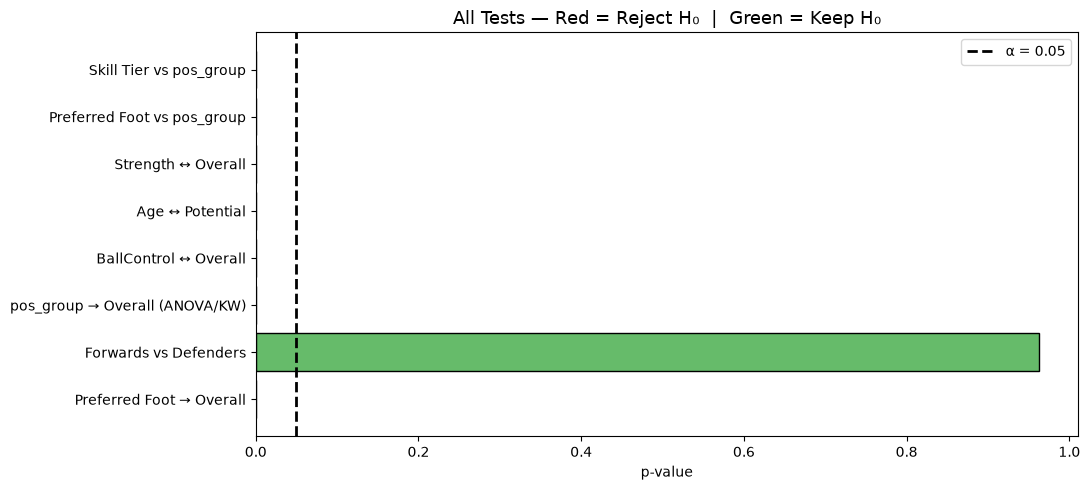

In [32]:
# 7b — Final p-value Bar Chart
test_labels = [
    'Preferred Foot → Overall',
    'Forwards vs Defenders',
    'pos_group → Overall (ANOVA/KW)',
    'BallControl ↔ Overall',
    'Age ↔ Potential',
    'Strength ↔ Overall',
    'Preferred Foot vs pos_group',
    'Skill Tier vs pos_group',
]

p_values = results_df['p_value'].tolist()
 # ← fill in your p-values

colors = ["#dd3b0a" if p is not None and p <= 0.05 else '#66bb6a' for p in p_values]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(test_labels, p_values, color=colors, edgecolor='black')
ax.axvline(0.05, color='black', linestyle='--', linewidth=2, label='α = 0.05')
ax.set_xlabel('p-value')
ax.set_title('All Tests — Red = Reject H₀  |  Green = Keep H₀', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show() 


---
### 7c. Scouting Team Brief ✍️ — Written Section (5 marks)

Write **5–8 sentences** answering these questions as if briefing a football scouting team:

> 1. **Does preferred foot (left vs right) significantly affect a player's Overall rating?**
>    What did the test show, and what does that mean for scouting?
>
> 2. **Which position group has the highest average Overall?** Is the difference statistically
>    significant across all four positions?
>
> 3. **What is the single strongest predictor of a player's Overall rating?**
>    Refer to your correlation values.
>
> 4. **What happens to a player's Potential as they age?** Is this relationship
>    statistically significant? What does this mean for investing in young players?
>
> 5. **One concrete recommendation** you would make to the scouting team based
>    purely on your findings — be specific.

*Write your brief below as comments or in a new markdown cell.*


In [ ]:
# 7c — Scouting Team Brief

# 1. Preferred foot vs Overall:
# Left-footed players had a significantly higher average Overall rating than
# right-footed players: 66.80 versus 66.09, with Mann–Whitney U p < 0.001.
# However, the difference was small, so preferred foot should not be used alone
# to select players.

# 2. Position group with highest Overall — is it significant?
# Midfielders had the highest average Overall rating at approximately 66.55.
# The Kruskal–Wallis test was significant, p < 0.001, showing that at least one
# position group differed. Tukey results showed that GK ratings were significantly
# lower than Defender, Forward, and Midfielder ratings.

# 3. Strongest predictor of Overall:
# BallControl was the strongest tested attribute associated with Overall, 
# with a moderate positive Pearson correlation of r = 0.4600 and p < 0.001.

# 4. Age vs Potential — what happens as players get older?
# Potential decreases as Age increases. Spearman's correlation was rho = -0.2623
# with p < 0.001, showing a statistically significant negative relationship.
# Therefore, younger players with high Potential may offer better long-term
# development opportunities.

# 5. Your recommendation to the scouting team:
# Prioritise younger players with high Potential and strong BallControl, especially
# midfielders and forwards. Use preferred foot as a supporting factor rather than
# as the main selection criterion, and evaluate goalkeepers separately because
# their Overall ratings differ from the outfield position groups.



---
---
# 🏆 Marking Scheme
*(For instructor use)*

| Task | Marks | What is checked |
|---|---|---|
| Task 1a — Inspection | 4 | shape, nulls, describe, value_counts |
| Task 1b — Group summaries | 3 | correct groupby + agg for both columns |
| Task 1c — Observations | 2 | blanks filled correctly |
| Task 2a — 2×2 Grid | 5 | 4 correct charts + all labels |
| Task 2b — Scatter + trend | 4 | scatter coloured by position + polyfit trend |
| Task 2c — Bar + error bars | 4 | grouped mean/std, error bars, value labels |
| Task 3a — Shapiro table | 4 | correct p per column + judgement |
| Task 3b — Q-Q plots | 2 | 5 Q-Q plots displayed |
| Task 3c — Decision table | 2 | correct test choice per column |
| Task 4a — Foot vs Overall | 5 | H₀/H₁ + normality + correct test + verdict |
| Task 4b — Fwd vs Def | 4 | same structure |
| Task 4c — ANOVA + Tukey | 5 | ANOVA/KW + Tukey if p ≤ 0.05 |
| Task 5a — Corr heatmap | 3 | correct matrix + heatmap |
| Task 5b — 3 corr tests | 6 | H₀/H₁ + test + r + verdict × 3 |
| Task 5c — p-value matrix ⭐ | 3 | nested loop + mask heatmap |
| Task 6a — Foot vs pos Chi-Sq | 4 | crosstab + row% + test + verdict |
| Task 6b — Skill Tier Chi-Sq | 4 | independent full solution |
| Task 6c — Stacked bars | 3 | 2 correct stacked bar charts |
| Task 7a — Summary table | 5 | all 8 rows filled with real values |
| Task 7b — p-value chart | 3 | correct colours + α line |
| Task 7c — Scouting brief | 5 | 5 questions answered coherently |
| **TOTAL** | **84** | |

---

### ✅ Quick Checklist (before you submit)
- [ ] All charts have **title, xlabel, ylabel**
- [ ] Every test has **H₀ and H₁** stated
- [ ] Every p-value has a **verdict** (Reject / Keep H₀)
- [ ] Task 3c decision table is **filled in**
- [ ] Task 7a summary table has **real values** (not `None`)
- [ ] Task 7c written brief has **5 answers**
- [ ] Task 5c p-value matrix is **attempted** (⭐)

---
*The beautiful game, made more beautiful with data. ⚽📊*
